[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nlavadodatasci/atd-megaf-fiabilidade/blob/main/T4_dados_censurados/T4_dados_censurados.ipynb)

# T4 — Dados censurados e estimador de Kaplan–Meier

**ATD — MEGAF 2026/27 · Atividade de Fiabilidade · Tema T4**

Quando a observação termina e ainda há unidades a funcionar, só se sabe que essas unidades duraram **pelo menos** o tempo observado. São dados censurados. Este *notebook* mostra, com um exemplo inventado e com os dados da aula, o erro que se comete ao ignorá-los e a forma correta de os usar.

**Como usar:** execute as células por ordem (Shift+Enter). As primeiras secções estão resolvidas, com dados da aula ou com exemplos inventados, para mostrar o método. A última secção, **A sua vez**, lê os dados da instalação e deixa pistas: o trabalho do grupo começa aí. O capítulo deste tema no documento de apoio explica cada passo.

## 1. Preparação

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO = "https://raw.githubusercontent.com/nlavadodatasci/atd-megaf-fiabilidade/main/dados/"

def obter(ficheiro):
    """Vai buscar o ficheiro ao repositório. Se falhar, abre uma janela
    para o escolher no seu computador."""
    if not os.path.exists(ficheiro):
        try:
            urllib.request.urlretrieve(REPO + ficheiro, ficheiro)
        except Exception:
            from google.colab import files
            print("Escolha no seu computador o ficheiro", ficheiro)
            carregados = files.upload()
            if ficheiro not in carregados:               # veio com outro nome: renomeia
                os.rename(list(carregados)[0], ficheiro)
    return ficheiro

try:
    import lifelines
except ImportError:                       # no Colab é preciso instalar a biblioteca
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lifelines"])
from lifelines import KaplanMeierFitter, WeibullFitter

## 2. Kaplan–Meier à mão, com oito unidades inventadas

Oito unidades em serviço. `falhou = 1` significa que a falha foi observada nesse instante; `falhou = 0` significa que a unidade ainda funcionava quando deixou de ser observada.

In [2]:
ex = pd.DataFrame({"tempo":  [150, 300, 420, 500, 610, 700, 800, 900],
                   "falhou": [  1,   0,   1,   0,   1,   1,   0,   0]})
ex

,tempo,falhou
0,150,1
1,300,0
2,420,1
3,500,0
4,610,1
5,700,1
6,800,0
7,900,0


O estimador de Kaplan–Meier percorre os instantes em que houve falhas. Em cada um:

- conta as unidades **em risco** (as que ainda estavam em observação imediatamente antes);
- calcula a fração que sobreviveu a esse instante: $1 - \dfrac{\text{falhas}}{\text{em risco}}$;
- multiplica pela fiabilidade anterior.

Uma unidade censurada não faz descer a curva, mas deixa de contar como "em risco" a partir do momento em que sai de observação. É assim que a informação que ela traz ("durou pelo menos isto") é aproveitada.

In [3]:
def kaplan_meier(tempo, falhou):
    tempo, falhou = np.asarray(tempo), np.asarray(falhou)
    R, linhas = 1.0, []
    for ti in np.unique(tempo[falhou == 1]):           # instantes com falhas
        em_risco = (tempo >= ti).sum()
        falhas = ((tempo == ti) & (falhou == 1)).sum()
        R = R * (1 - falhas / em_risco)
        linhas.append({"tempo": ti, "em_risco": em_risco, "falhas": falhas, "R": R})
    return pd.DataFrame(linhas)

kaplan_meier(ex["tempo"], ex["falhou"])

,tempo,em_risco,falhas,R
0,150,8,1,0.875000
1,420,6,1,0.729167
2,610,4,1,0.546875
3,700,3,1,0.364583


Confirme a primeira linha à mão: 8 unidades em risco, 1 falha, $R = 1 \times (1 - 1/8) = 0{,}875$. Na segunda, a unidade censurada às 300 h já saiu, ficam 6 em risco: $R = 0{,}875 \times (1 - 1/6)$.

A biblioteca `lifelines` faz o mesmo e desenha a curva em degraus:

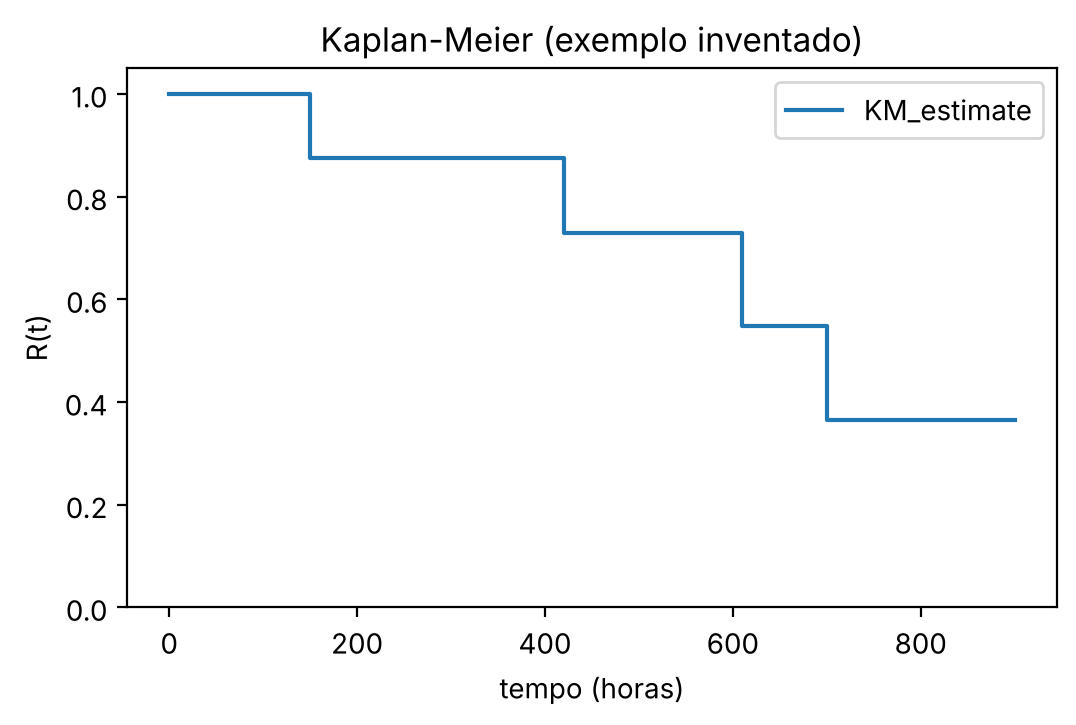

In [4]:
kmf = KaplanMeierFitter()
kmf.fit(ex["tempo"], event_observed=ex["falhou"])
kmf.plot_survival_function(ci_show=False, figsize=(6, 3.5))
plt.xlabel("tempo (horas)"); plt.ylabel("R(t)"); plt.ylim(0, 1.05); plt.title("Kaplan-Meier (exemplo inventado)")
plt.show()

## 3. O erro de ignorar a censura, visto nos dados da aula

Nos dados da aula todas as unidades falharam, por isso conhecemos a resposta certa (MTBF de cerca de 8738 h). Vamos fingir que a observação tinha terminado às **5000 h**: as unidades que duraram mais ficam censuradas nesse instante.

In [5]:
aula = pd.read_excel(obter("tempo_falhas_aula.xlsx"), sheet_name="tempo_falhas", usecols="A:B")
t = aula.iloc[:, 1].dropna().to_numpy()

fim = 5000
tempo_obs = np.minimum(t, fim)             # o que se teria registado
falhou = (t <= fim).astype(int)            # 1 = falha observada, 0 = censurado
print(f"Falhas observadas: {falhou.sum()} em {len(t)}  ({1 - falhou.mean():.0%} de dados censurados)")

print(f"MTBF verdadeiro (todos os dados):           {t.mean():8.0f} h")
print(f"Média só das unidades que falharam:         {tempo_obs[falhou == 1].mean():8.0f} h")
print(f"Média de tudo, como se fossem todas falhas: {tempo_obs.mean():8.0f} h")

Falhas observadas: 4340 em 9998  (57% de dados censurados)
MTBF verdadeiro (todos os dados):               8738 h
Média só das unidades que falharam:             2238 h
Média de tudo, como se fossem todas falhas:     3801 h


As duas contas "ingénuas" dão um MTBF muito abaixo do verdadeiro, porque deitam fora, ou tratam como falhas, precisamente as unidades que duraram mais.

Para a distribuição exponencial há uma correção simples: dividir o **tempo total de funcionamento** (de todas as unidades, censuradas incluídas) pelo **número de falhas observadas**.

In [6]:
print(f"Tempo total / n.º de falhas: {tempo_obs.sum() / falhou.sum():8.0f} h")

Tempo total / n.º de falhas:     8757 h


A curva de Kaplan–Meier, calculada só com o que se teria observado até às 5000 h, acompanha a fiabilidade verdadeira. A estimativa ingénua (só com as unidades que falharam) fica muito abaixo.

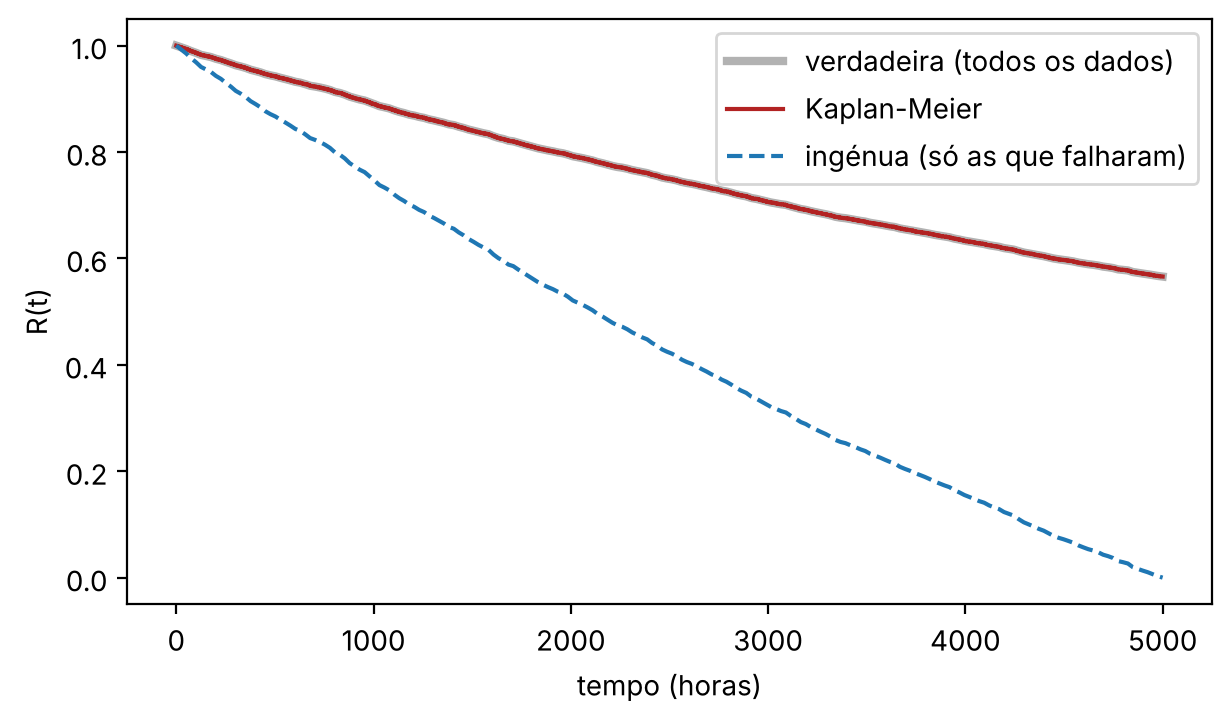

In [7]:
x = np.linspace(0, fim, 200)
kmf = KaplanMeierFitter().fit(tempo_obs, event_observed=falhou)

plt.figure(figsize=(7, 3.8))
plt.plot(x, [(t > v).mean() for v in x], color="black", lw=3, alpha=0.3, label="verdadeira (todos os dados)")
plt.step(kmf.survival_function_.index, kmf.survival_function_.iloc[:, 0], where="post", color="firebrick", label="Kaplan-Meier")
plt.plot(x, [(tempo_obs[falhou == 1] > v).mean() for v in x], "--", label="ingénua (só as que falharam)")
plt.xlabel("tempo (horas)"); plt.ylabel("R(t)"); plt.legend(); plt.show()

## 4. Ajustar uma Weibull com dados censurados

O `scipy.stats.weibull_min.fit` trata todos os tempos como falhas. A classe `WeibullFitter` da `lifelines` aceita a coluna que indica a censura. **Atenção aos nomes:** na `lifelines`, `rho_` é o parâmetro de forma ($\beta$) e `lambda_` é o de escala ($\eta$).

In [8]:
wf = WeibullFitter().fit(tempo_obs, event_observed=falhou)
print(f"beta (rho_) = {wf.rho_:.3f}    eta (lambda_) = {wf.lambda_:.0f} h")

beta (rho_) = 0.980    eta (lambda_) = 8885 h


Com mais de metade das unidades por falhar, o ajuste recupera $\beta \approx 1$ e $\eta$ próximo do MTBF verdadeiro.

## 5. A sua vez

A folha `frota_campo` tem controladores e geradores em serviço. Pistas:

1. Que percentagem de cada componente está censurada? Qual é o maior tempo observado?
2. Calcule a estimativa ingénua de $R(t)$ (só com as unidades que falharam) e a de Kaplan–Meier, e desenhe-as no mesmo gráfico. Para que lado erra a ingénua?
3. Ajuste uma Weibull com censura a cada componente e sobreponha-a à curva de Kaplan–Meier.
4. A curva de Kaplan–Meier não vai além do maior tempo observado. O que é preciso para dizer alguma coisa sobre tempos maiores, e com que riscos?
5. Compare os parâmetros com os que se obtêm dos ensaios de vida (folha `ensaios_vida`) para os mesmos componentes. Deviam ser parecidos?
6. Para a missão de 2000 h, quanto vale $R(2000)$ segundo cada método?

In [9]:
frota = pd.read_excel(obter("dados_fiabilidade.xlsx"), sheet_name="frota_campo")
print(frota.groupby("componente")["falhou"].agg(["count", "sum"]))

componente = "Controlador"                     # depois: "Gerador"
d = frota[frota["componente"] == componente]
# KaplanMeierFitter().fit(d["tempo_observado_h"], event_observed=d["falhou"])

             count  sum
componente             
Controlador     80   27
Gerador         80   40
